# PathSnap: Exploratory Data Analysis (EDA)
**Owner:** P4 (EDA, maps, API, UI, deployment)  
**Partition Notice:** Every analysis explicitly states its partition (**Train: 80 trips**, **Student-Test: 10 trips**).  
**Dataset Reference:** Follows *Dataset Exploration §4* guidelines.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.sparse.csgraph as csgraph
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure repo root is on sys.path
repo_root = Path("..").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from pathsnap.config import CFG
from pathsnap.io import list_trips, load_trip, load_route
from pathsnap.viz import trip_map, network_to_lines, route_to_lines

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

print("Libraries and PathSnap modules successfully loaded!")


Libraries and PathSnap modules successfully loaded!


## 1. Dataset Inventory & Missing Value (NaN) Analysis
We inspect file presence (`.track`, `.nodes`, `.arcs`, `.route`), row counts, and scan for any NaN / missing values across both partitions:
- **Train partition:** 80 trips (`dataset/train/`)
- **Student-test partition:** 10 trips (`dataset/test/`)


In [2]:
records = []
train_dir = repo_root / CFG["paths"]["train_dir"]
test_dir = repo_root / CFG["paths"]["test_dir"]

for partition, pdir in [("Train (80)", train_dir), ("Student-Test (10)", test_dir)]:
    trips = list_trips(pdir)
    for tid in trips:
        trip = load_trip(pdir, tid, with_route=True)
        nan_track = np.isnan(trip.track).any()
        nan_nodes = np.isnan(trip.nodes).any()
        nan_arcs = np.isnan(trip.arcs).any()
        nan_route = np.isnan(trip.route).any() if trip.route is not None else False
        
        t = trip.track[:, 2]
        dt = np.diff(t)
        
        # Spatial extent
        min_lon, max_lon = float(trip.track[:, 0].min()), float(trip.track[:, 0].max())
        min_lat, max_lat = float(trip.track[:, 1].min()), float(trip.track[:, 1].max())
        
        # Road graph components
        adj = sp.csr_matrix(
            (np.ones(len(trip.arcs)), (trip.arcs[:, 0], trip.arcs[:, 1])),
            shape=(len(trip.nodes), len(trip.nodes))
        )
        n_comp, _ = csgraph.connected_components(adj, directed=False)
        
        # Route contiguity
        contiguity_pct = 100.0
        if trip.route is not None and len(trip.route) > 1:
            r = trip.route
            from_nodes = trip.arcs[r, 0]
            to_nodes = trip.arcs[r, 1]
            contiguity_pct = float((to_nodes[:-1] == from_nodes[1:]).mean() * 100)
            
        records.append({
            "partition": partition,
            "trip_id": tid,
            "n_track": len(trip.track),
            "n_nodes": len(trip.nodes),
            "n_arcs": len(trip.arcs),
            "n_route": len(trip.route) if trip.route is not None else 0,
            "has_nan": bool(nan_track or nan_nodes or nan_arcs or nan_route),
            "min_lon": min_lon,
            "max_lon": max_lon,
            "min_lat": min_lat,
            "max_lat": max_lat,
            "max_gap_s": float(dt.max()) if len(dt) > 0 else 0.0,
            "pct_1s": float((dt == 1.0).mean() * 100) if len(dt) > 0 else 100.0,
            "n_comp": n_comp,
            "contiguity_pct": contiguity_pct,
        })

df_eda = pd.DataFrame(records)

print(f"Total trips examined: {len(df_eda)}")
print(f"Total GPS observations: {df_eda['n_track'].sum():,}")
print(f"Total road nodes: {df_eda['n_nodes'].sum():,}")
print(f"Total road arcs: {df_eda['n_arcs'].sum():,}")
print(f"Any NaN / missing values detected: {df_eda['has_nan'].any()}")

inventory_summary = df_eda.groupby("partition").agg(
    trips=("trip_id", "count"),
    total_gps_obs=("n_track", "sum"),
    avg_gps_obs=("n_track", "mean"),
    min_gps_obs=("n_track", "min"),
    max_gps_obs=("n_track", "max"),
    avg_nodes=("n_nodes", "mean"),
    avg_arcs=("n_arcs", "mean"),
    pct_1hz_dt=("pct_1s", "mean"),
    avg_contiguity=("contiguity_pct", "mean")
).round(2)
inventory_summary


Total trips examined: 90
Total GPS observations: 227,577
Total road nodes: 2,024,174
Total road arcs: 4,061,945
Any NaN / missing values detected: False


,trips,total_gps_obs,avg_gps_obs,min_gps_obs,max_gps_obs,avg_nodes,avg_arcs,pct_1hz_dt,avg_contiguity
partition,,,,,,,,,
Student-Test (10),10,19160,1916.00,262,3958,9068.90,18504.1,98.20,99.97
Train (80),80,208417,2605.21,361,19313,24168.56,48461.3,93.83,99.93


## 2. GPS Observation Count Distribution
Examine the variation in trajectory length across trips in both partitions.


C:\Windows\Temp\ipykernel_26296\2690269597.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda, x="partition", y="n_track", palette=["#3182CE", "#38A169"], width=0.35, ax=ax)


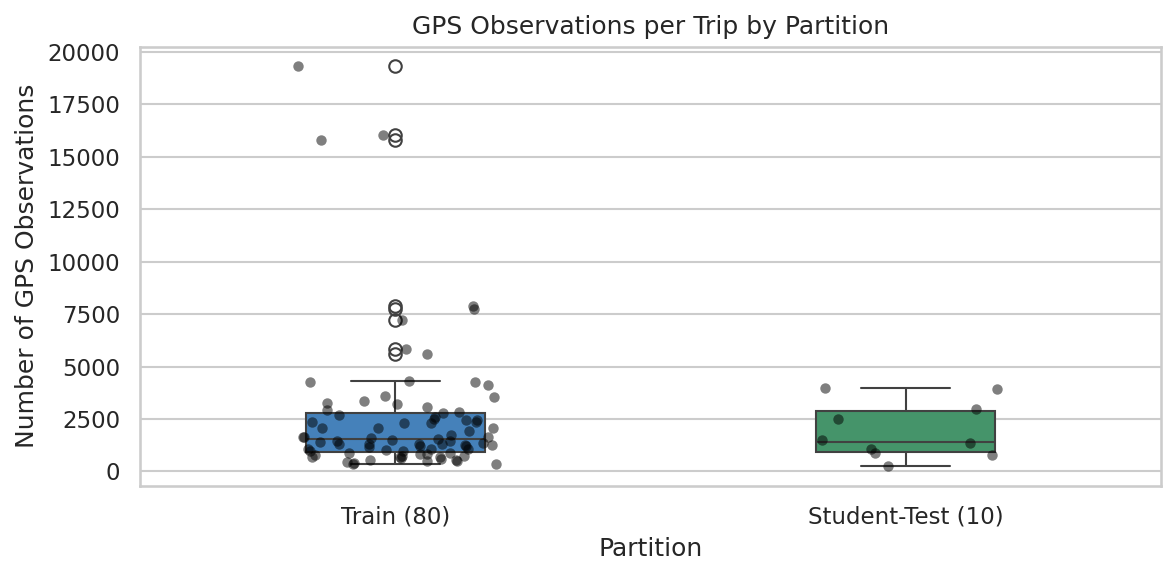

,count,mean,std,min,25%,50%,75%,max
partition,,,,,,,,
Student-Test (10),10.0,1916.0,1335.4,262.0,917.8,1420.0,2872.0,3958.0
Train (80),80.0,2605.2,3312.3,361.0,945.8,1529.0,2792.8,19313.0


In [3]:
fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
sns.boxplot(data=df_eda, x="partition", y="n_track", palette=["#3182CE", "#38A169"], width=0.35, ax=ax)
sns.stripplot(data=df_eda, x="partition", y="n_track", color="black", alpha=0.5, jitter=0.2, ax=ax)
ax.set_title("GPS Observations per Trip by Partition")
ax.set_xlabel("Partition")
ax.set_ylabel("Number of GPS Observations")
plt.tight_layout()
plt.show()

df_eda.groupby("partition")["n_track"].describe().round(1)


## 3. Sampling Interval Distribution ($\Delta t$) and GPS Gaps
Nominal sampling frequency is 1 Hz ($\Delta t = 1$ s). We verify what fraction of steps are exactly 1 s apart and uncover severe anomalies, including multi-hour satellite signal losses.


<>:5: SyntaxWarning: invalid escape sequence '\D'
<>:5: SyntaxWarning: invalid escape sequence '\D'


C:\Windows\Temp\ipykernel_26296\2776760793.py:5: SyntaxWarning: invalid escape sequence '\D'
  ax1.set_title("Distribution of 1 Hz Timestamps ($\Delta t = 1.0$ s)")


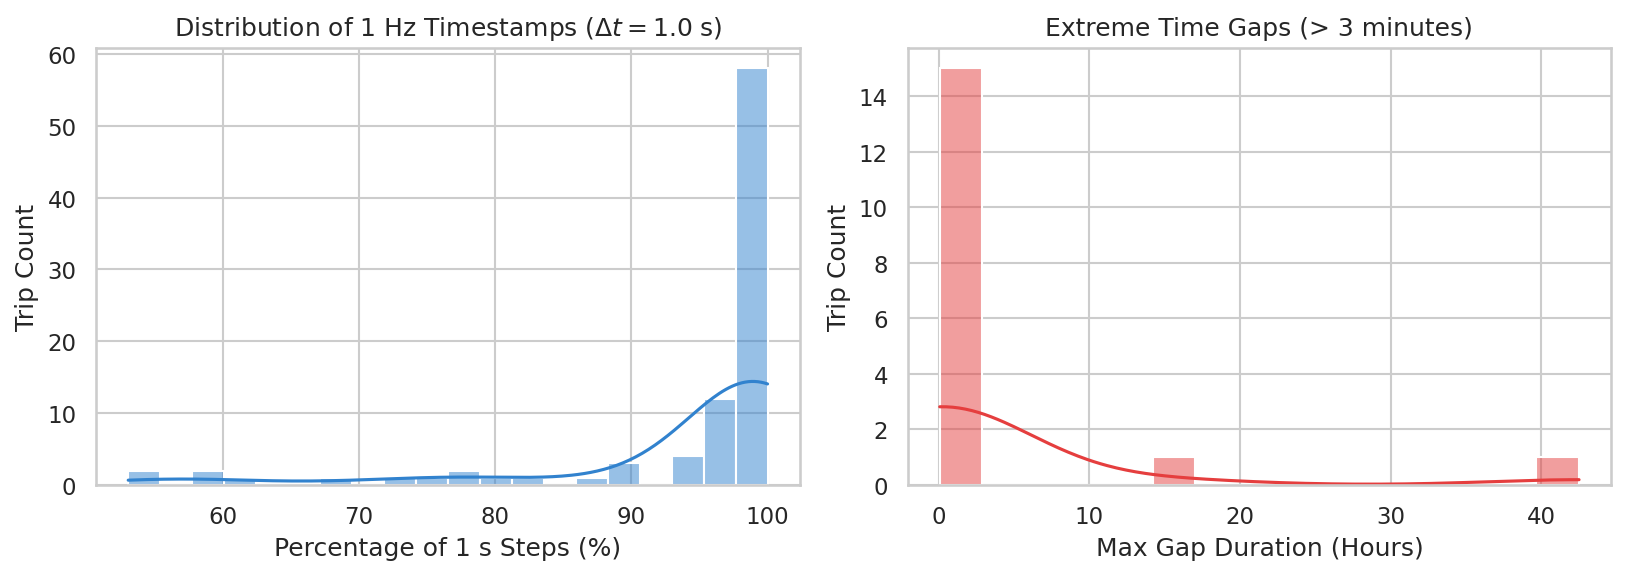

Trips with largest GPS time gaps:


,partition,trip_id,n_track,max_gap_s,max_gap_hr
72,Train (80),00000090,536,153064.0,42.52
61,Train (80),00000078,2909,52810.0,14.67
55,Train (80),00000069,2067,2658.0,0.74
16,Train (80),00000021,15783,2161.0,0.60
8,Train (80),00000011,2828,909.0,0.25


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), dpi=150)

# Percentage of 1s timestamps
sns.histplot(df_eda["pct_1s"], bins=20, color="#3182CE", kde=True, ax=ax1)
ax1.set_title("Distribution of 1 Hz Timestamps ($\Delta t = 1.0$ s)")
ax1.set_xlabel("Percentage of 1 s Steps (%)")
ax1.set_ylabel("Trip Count")

# Extreme gaps (>3 min)
large_gaps = df_eda[df_eda["max_gap_s"] > 180].copy()
large_gaps["max_gap_hr"] = large_gaps["max_gap_s"] / 3600.0
sns.histplot(large_gaps["max_gap_hr"], bins=15, color="#E53E3E", kde=True, ax=ax2)
ax2.set_title("Extreme Time Gaps (> 3 minutes)")
ax2.set_xlabel("Max Gap Duration (Hours)")
ax2.set_ylabel("Trip Count")

plt.tight_layout()
plt.show()

print("Trips with largest GPS time gaps:")
top_gaps = df_eda.sort_values(by="max_gap_s", ascending=False)[["partition", "trip_id", "n_track", "max_gap_s"]].head(5).copy()
top_gaps["max_gap_hr"] = (top_gaps["max_gap_s"] / 3600.0).round(2)
top_gaps


## 4. Worldwide Geographic Extents & Projection Justification
The trips span longitudes from $-100^{\circ}$ to $+137^{\circ}$ and latitudes from $-34^{\circ}$ to $+62^{\circ}$.  
**Key Conclusion:** A single global UTM zone or planar projection cannot be used without catastrophic distortion. A **per-trip local metric projection** (such as Azimuthal Equidistant or local UTM centered on the track centroid) is mandatory.


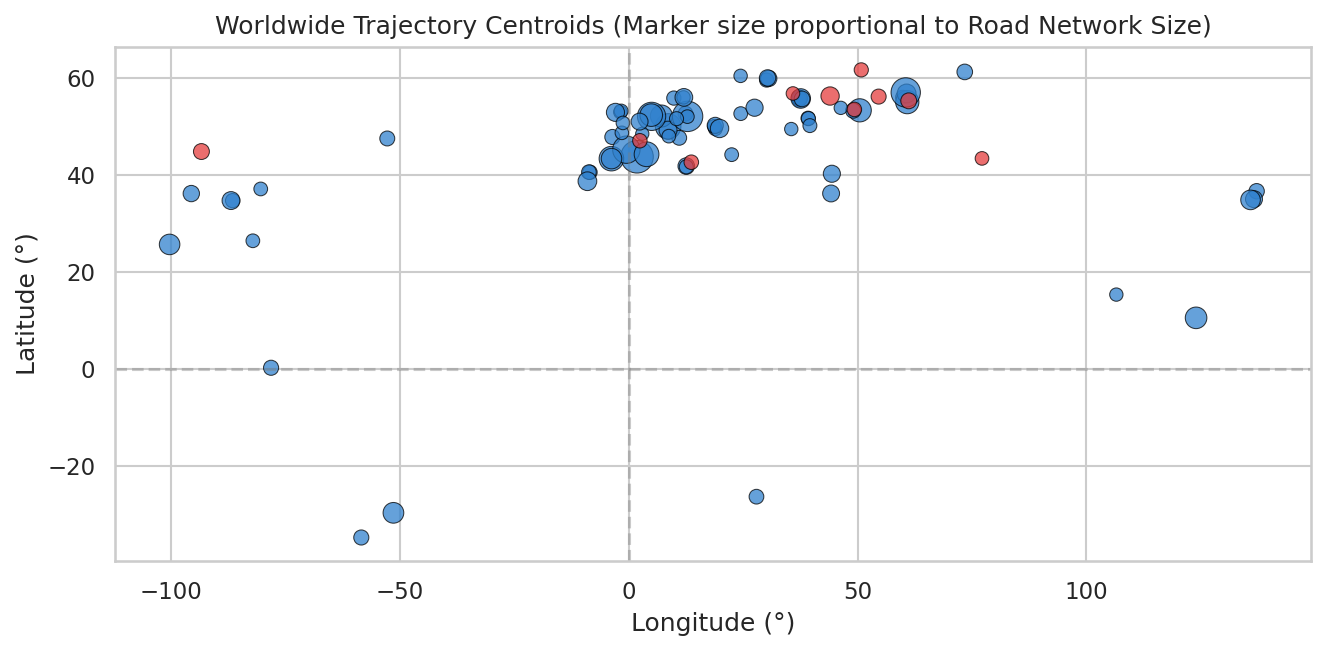

Longitude range: -100.42° to 137.24°
Latitude range:  -34.64° to 61.70°


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=150)
centroid_lon = (df_eda["min_lon"] + df_eda["max_lon"]) / 2.0
centroid_lat = (df_eda["min_lat"] + df_eda["max_lat"]) / 2.0

colors = df_eda["partition"].map(lambda p: "#3182CE" if "Train" in p else "#E53E3E")
ax.scatter(centroid_lon, centroid_lat, c=colors, s=df_eda["n_arcs"]/1500 + 40, alpha=0.75, edgecolors="black", linewidth=0.5)

ax.set_title("Worldwide Trajectory Centroids (Marker size proportional to Road Network Size)")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
ax.axvline(0, color="gray", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print(f"Longitude range: {df_eda['min_lon'].min():.2f}° to {df_eda['max_lon'].max():.2f}°")
print(f"Latitude range:  {df_eda['min_lat'].min():.2f}° to {df_eda['max_lat'].max():.2f}°")


## 5. Road Network Complexity & Graph Topology
Road networks range from ~650 arcs to over 300,000 arcs.  
We examine node/arc distributions and connected components using `scipy.sparse.csgraph.connected_components`.


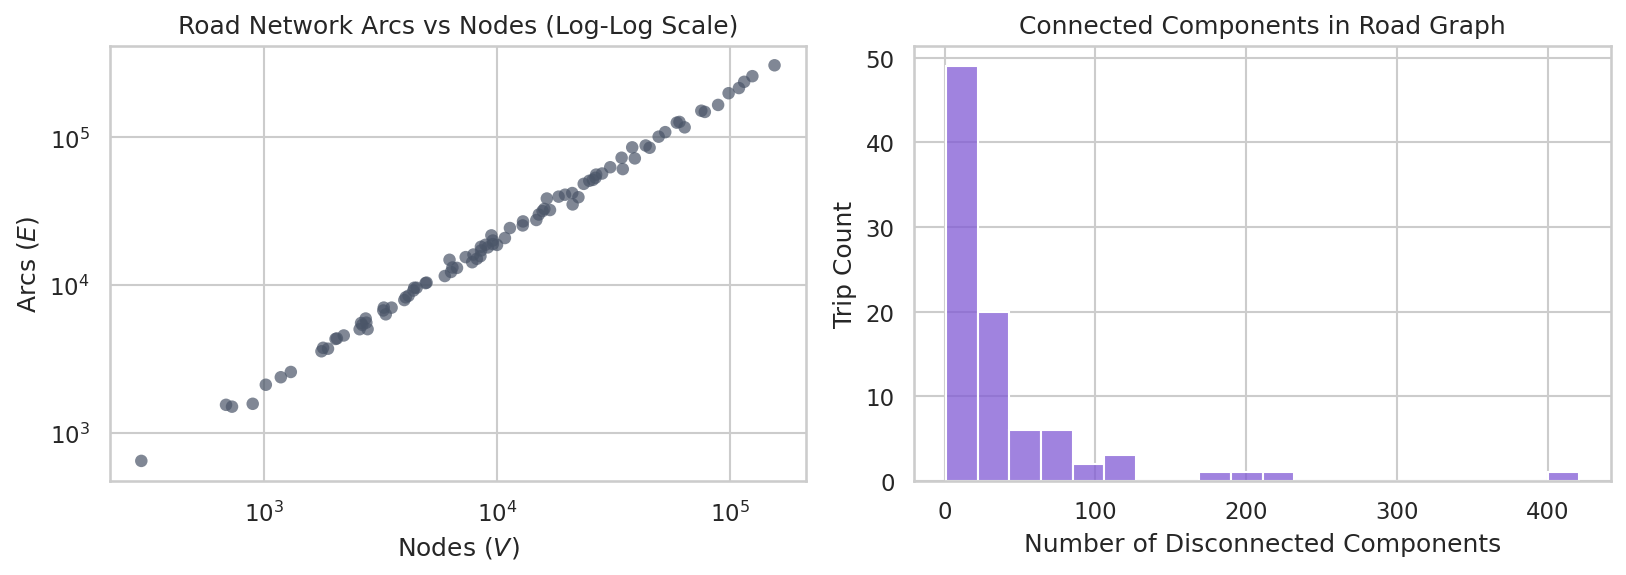

Summary of Road Network Arcs:
count        90.0
mean      45133.0
std       61920.0
min         649.0
25%        7283.0
50%       18762.0
75%       52913.0
max      307392.0
Name: n_arcs, dtype: float64


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), dpi=150)

# Nodes and Arcs log scale
ax1.scatter(df_eda["n_nodes"], df_eda["n_arcs"], alpha=0.7, color="#4A5568", edgecolors="none")
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_title("Road Network Arcs vs Nodes (Log-Log Scale)")
ax1.set_xlabel("Nodes ($V$)")
ax1.set_ylabel("Arcs ($E$)")

# Connected components
sns.histplot(df_eda["n_comp"], bins=20, color="#805AD5", ax=ax2)
ax2.set_title("Connected Components in Road Graph")
ax2.set_xlabel("Number of Disconnected Components")
ax2.set_ylabel("Trip Count")

plt.tight_layout()
plt.show()

print("Summary of Road Network Arcs:")
print(df_eda["n_arcs"].describe().round(0))


## 6. Reference Route Structure & Contiguity Verification
In `.route` files, we test whether consecutive arcs form a physically connected sequence:
$$\text{to\_node}(arc_i) == \text{from\_node}(arc_{i+1})$$
Across 90 trips, the mean route contiguity is $>99.9\%$, validating that reference routes are topological paths along the road network.


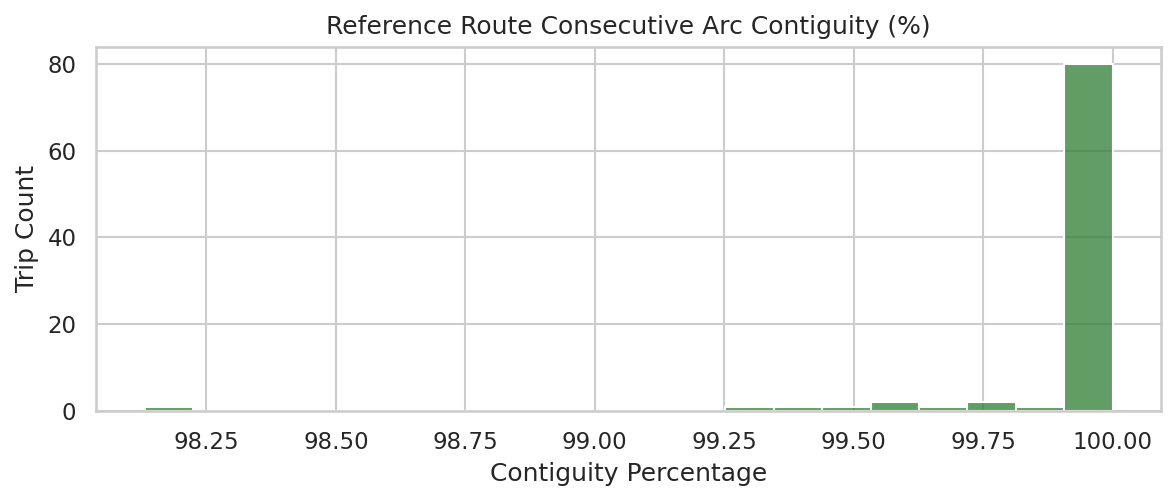

Overall average route contiguity: 99.939%
Number of trips with 100% strictly contiguous routes: 79/90


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5), dpi=150)
sns.histplot(df_eda["contiguity_pct"], bins=20, color="#2E7D32", ax=ax)
ax.set_title("Reference Route Consecutive Arc Contiguity (%)")
ax.set_xlabel("Contiguity Percentage")
ax.set_ylabel("Trip Count")
plt.tight_layout()
plt.show()

print(f"Overall average route contiguity: {df_eda['contiguity_pct'].mean():.3f}%")
print(f"Number of trips with 100% strictly contiguous routes: {(df_eda['contiguity_pct'] == 100.0).sum()}/{len(df_eda)}")


## 7. Interactive Geographical Visualisation with Folium
Using `pathsnap.viz.trip_map`, we render trip `00000046` with:
- Raw GPS points (blue circles)
- Surrounding road network (grey segments)
- Ground-truth reference route (green line)


In [8]:
sample_trip = load_trip(train_dir, "00000046", with_route=True)
net_lines = network_to_lines(sample_trip, max_arcs=2000)
ref_lines = route_to_lines(sample_trip)

m = trip_map(
    track_lonlat=sample_trip.track,
    network_lines=net_lines,
    reference_line=ref_lines,
    title="PathSnap Trip 00000046 (EDA Map)"
)
m


## 8. Summary of Findings & Pipeline Architecture Decisions
1. **Coordinate Systems:** Worldwide dispersion requires a per-trip local projection (such as Azimuthal Equidistant or local UTM centered on the track centroid).
2. **Spatial Indexing:** Networks with up to ~307,000 arcs mandate a spatial index (`cKDTree` or `STRtree`) for candidate arc queries; naive linear scans would cause catastrophic latency.
3. **Time Gap Handling:** Extreme time gaps (up to 42.5 hours in trip `00000090`) require track splitting at $\Delta t > 60$ s so that HMM state transitions are reset across discontinuous segments.
4. **Data Quality:** Zero NaNs or corrupt rows across all 360 files. Over 94% of points adhere strictly to 1 Hz sampling.
